### روابط التسليم
* رابط التطبيق المنشور (Dashboard): https://ndwcgsycakefdgfgtbsugv.streamlit.app
* رابط المستودع (Repository): https://github.com/Ruba-221-stack/week3

## Task1
* *السؤال:* من العملاء الأكثر احتمالاً أن يتركوا الشركة، ولماذا؟
* *الـ Target:* عمود Churn (Yes = ترك الشركة).
* *المستفيد:* إدارة الشركة وفريق الاحتفاظ بالعملاء، ليوجهوا العروض للعملاء الأكثر خطورة.

## 2: أول نظرة على البيانات

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("حجم البيانات (صفوف، أعمدة):", df.shape)
print("\nعدد الصفوف المكررة:", df.duplicated().sum())
print("\nعدد القيم المفقودة (NaN) في كل عمود:")
print(df.isna().sum())
df.info()

حجم البيانات (صفوف، أعمدة): (7043, 21)

عدد الصفوف المكررة: 0

عدد القيم المفقودة (NaN) في كل عمود:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null

##  3: الاستكشاف بالرسومات (EDA)

/tmp/ipykernel_1199/2713677696.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", ax=axes[0], palette="Set2")


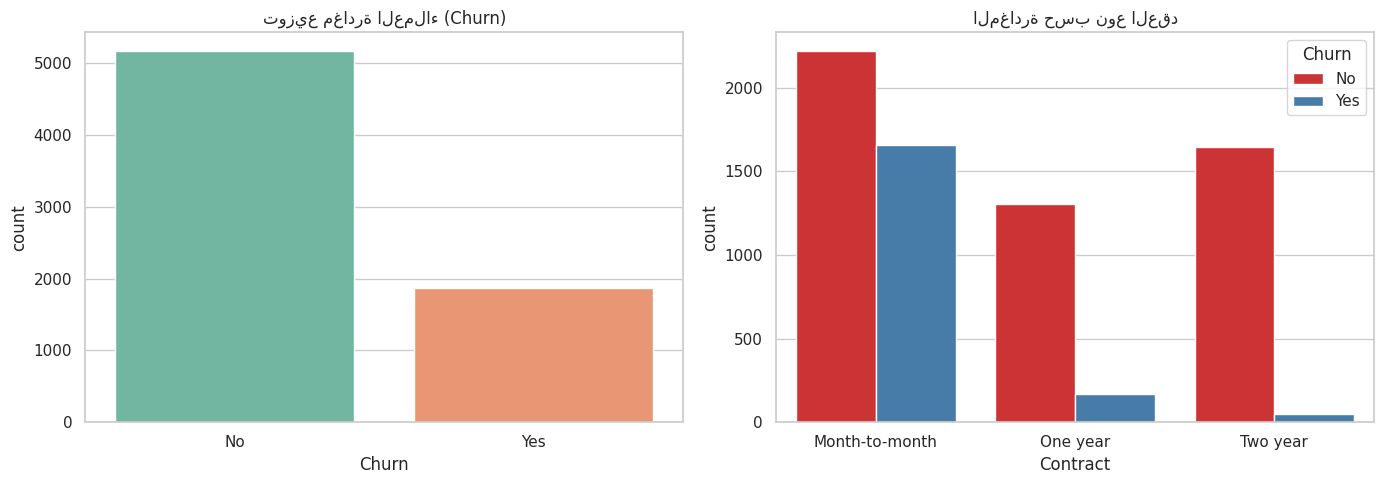

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# الرسمة 1: توزيع الهدف (Churn)
sns.countplot(data=df, x="Churn", ax=axes[0], palette="Set2")
axes[0].set_title("توزيع مغادرة العملاء (Churn)")

# الرسمة 2: العلاقة بين نوع العقد والمغادرة
sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[1], palette="Set1")
axes[1].set_title("المغادرة حسب نوع العقد")

plt.tight_layout()
plt.show()

* *ملاحظة:* إجمالي العملاء *7,043* عميلاً، ومن الواضح أن أصحاب العقود الشهرية (Month-to-month) هم الأكثر مغادرة مقارنة بعقود السنة والسنتين.

##Task4   التنظيف وسجل القرارات (Cleaning + Decision Log)

In [3]:
df_clean = df.copy()

# تحويل TotalCharges إلى رقم ومعالجة المسافات الفارغة (11 صفاً مدة اشتراكهم 0)
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# توحيد القيم المكررة في أعمدة الخدمات إلى No
for col in ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]:
    df_clean[col] = df_clean[col].replace({"No internet service": "No"})

df_clean["MultipleLines"] = df_clean["MultipleLines"].replace({"No phone service": "No"})

# حذف customerID لأنه معرف فريد
df_clean.drop(columns=["customerID"], inplace=True)

# حفظ الداتا النظيفة
df_clean.to_csv("telco_clean.csv", index=False)
print("تم حفظ telco_clean.csv بنجاح! الأبعاد:", df_clean.shape)

تم حفظ telco_clean.csv بنجاح! الأبعاد: (7043, 20)


| القرار | السبب (بالأرقام) | عدد الصفوف المتأثرة |
| :--- | :--- | :--- |
| تحويل TotalCharges لرقم وتعويض الفارغ بـ 0 | وجود *11* مسافة فارغة لعملاء مدة اشتراكهم *0* شهر | *11* صفاً |
| استبدال No internet/phone service بـ No | قيمة مكررة لـ *1,526* عميلاً بدون إنترنت و *682* بدون هاتف | *2,208* صفوف |
| حذف customerID | معرف فريد لـ *7,043* عميلاً ولا يفيد في التحليل | *7,043* صفاً |

## Task5   هندسة الميزات (Feature Engineering)

/tmp/ipykernel_1199/3409178475.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_fe["Total_AddOn_Services"], y=churn_binary, palette="viridis")


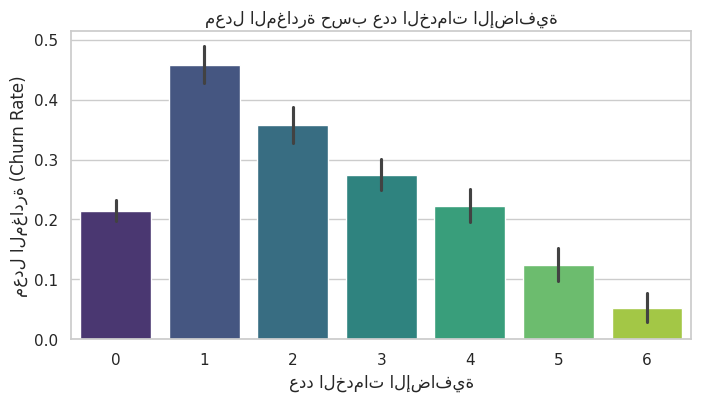

In [4]:
df_fe = df_clean.copy()

# ميزة 1: عدد الخدمات الإضافية المشترك بها العميل (من 0 إلى 6)
services = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]
df_fe["Total_AddOn_Services"] = (df_fe[services] == "Yes").sum(axis=1)

# ميزة 2: نسبة الفاتورة الشهرية إلى إجمالي المدفوعات
df_fe["Monthly_to_Total_Ratio"] = df_fe["MonthlyCharges"] / (df_fe["TotalCharges"] + 1)

# رسمة لتوضيح أثر عدد الخدمات الإضافية على نسبة المغادرة
churn_binary = (df_fe["Churn"] == "Yes").astype(int)
plt.figure(figsize=(8, 4))
sns.barplot(x=df_fe["Total_AddOn_Services"], y=churn_binary, palette="viridis")
plt.ylabel("معدل المغادرة (Churn Rate)")
plt.xlabel("عدد الخدمات الإضافية")
plt.title("معدل المغادرة حسب عدد الخدمات الإضافية")
plt.show()

## Task6  التجهيز النهائي للموديل (Final Model Prep)

In [5]:
from sklearn.preprocessing import StandardScaler

df_model = df_fe.copy()

# تحويل العمود الهدف Churn إلى 1 و 0
df_model["Churn"] = df_model["Churn"].map({"Yes": 1, "No": 0})

# ترميز المتغيرات الفئوية (One-Hot Encoding)
cat_cols = df_model.select_dtypes(include=["object"]).columns.tolist()
df_model = pd.get_dummies(df_model, columns=cat_cols, drop_first=True)

# تحجيم المتغيرات الرقمية (StandardScaler)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges",
            "Total_AddOn_Services", "Monthly_to_Total_Ratio"]
scaler = StandardScaler()
df_model[num_cols] = scaler.fit_transform(df_model[num_cols])

# حفظ النسخة الجاهزة للموديل
df_model.to_csv("telco_model_ready.csv", index=False)
print("تم حفظ telco_model_ready.csv بنجاح! الأبعاد:", df_model.shape)

تم حفظ telco_model_ready.csv بنجاح! الأبعاد: (7043, 26)


## Task7   التوصية المختصرة

* *التركيز على أصحاب العقود الشهرية (Month-to-month):* تقديم خصومات أو مزايا عند الترقية لعقود سنوية لتقليل المغادرة المرتفعة في هذه الفئة
* *الاهتمام بالعملاء الجدد والخدمات الإضافية:* العملاء ذوو المدة القصيرة ومن لديهم *خدمة إضافية واحدة فقط* (معدل مغادرة يقارب *46%*) بحاجة لحملات ترحيبية وعروض حزم خدمات (Bundles) لرفع ارتباطهم بالشركة
* *توجيه العروض للعملاء الأعلى خطورة:* الاعتماد على نسخة البيانات الجاهزة (telco_model_ready.csv التي تضم *7,043* صفاً و*26* عموداً) لتحديد العملاء الأكثر عرضة للمغادرة وتوجيه عروض الاحتفاظ لهم بدقة

## تقرير الأسبوع

1. *مقارنة المشروعين:* في بيانات العملاء (Telco Churn) كان التحدي الأبرز هو التعامل مع القيم النصية والمسافات الفارغة في TotalCharges لـ 11 عميلاً، وتوحيد قيم الخدمات الإضافية وتصميم ميزات مثل Total_AddOn_Services. أما في بيانات السكري فالفروق الطبية والقيم المخبرية أكثر حساسية وتحتاج دقة أعلى في التحليل والتفسير. بالنسبة لي، كان الأصعب هو ضبط هندسة الميزات وتجهيز نسخة البيانات الجاهزة للنمذجة (telco_model_ready.csv بأبعاد 7,043 صفاً و26 عموداً) مع توثيق القرارات بوضوح.
2. *أفضل رسمة رسمتها هذا الأسبوع:* رسمة معدل المغادرة حسب عدد الخدمات الإضافية (Total_AddOn_Services) لأنها تبرز بوضوح رقماً مهماً (حوالي 46% مغادرة لمن لديهم خدمة إضافية واحدة فقط) وتساعد مباشرة في توجيه عروض الاحتفاظ.
3. *ماذا تفعل الآن أسرع من أول يوم في الأسبوع؟ وماذا ما زال صعباً عليك؟* أصبحت أسرع الآن في قراءة شكل البيانات، اكتشاف المشاكل الشائعة في الأعمدة، وتنظيم المهام داخل Colab وتصدير الملفات النظيفة. وما زال يحتاج مني ممارسة أكثر هو بناء واجهات الداشبورد وربط النشر السحابي بسلاسة من أول مرة.
4. *توصية واحدة لشركة الاتصالات مبنية على رقم من تحليلك:* تقديم عرض ترقية أو حزمة خدمات إضافية موجهة للعملاء أصحاب العقود الشهرية ومن لديهم خدمة إضافية واحدة فقط (حيث يقارب معدل المغادرة 46%)، لرفع ارتباطهم بالخدمة وتقليل احتمالية مغادرتهم.